# **3. Data Representation**

### **3.1 Structure of the available data**

First, let's install the library "vrplib" by using the command : 

In [1]:
pip install vrplib

Defaulting to user installation because normal site-packages is not writeable
  Using cached vrplib-2.2.0-py3-none-any.whl.metadata (10.0 kB)
Using cached vrplib-2.2.0-py3-none-any.whl (15 kB)
Note: you may need to restart the kernel to use updated packages.


DEPRECATION: Loading egg at d:\anaconda\lib\site-packages\vboxapi-1.0-py3.11.egg is deprecated. pip 24.3 will enforce this behaviour change. A possible replacement is to use pip for package installation.. Discussion can be found at https://github.com/pypa/pip/issues/12330


The repository that was provided to us provides files with instances. They're located in the folder "test" and contain what we call "parsed data". By parsed data we mean raw text from an instance (our files) that will then be converted into structured Python dictionaries with the library vrplib. There are mainly 2 formats used to represent our instances :

### **VRPLIB :**

It's the standard format for the Capacitated Vehicle Routing Problem (CVRP).

They have the extension ".vrp" and contains the problem specifications and its data. 

The specifications are key-value pairs separated by a colon and data are value like arrays : the coordinates of the customer and the service times for example.

### **Solomon (VRPTW)**

Here what we'll focus on are the files using the "Solomon" format. The difference with the VRPLIB format is that this one involves a time window and they have the extension ".txt"

Here's an example of what the heading of a Solomon instance can look like: 

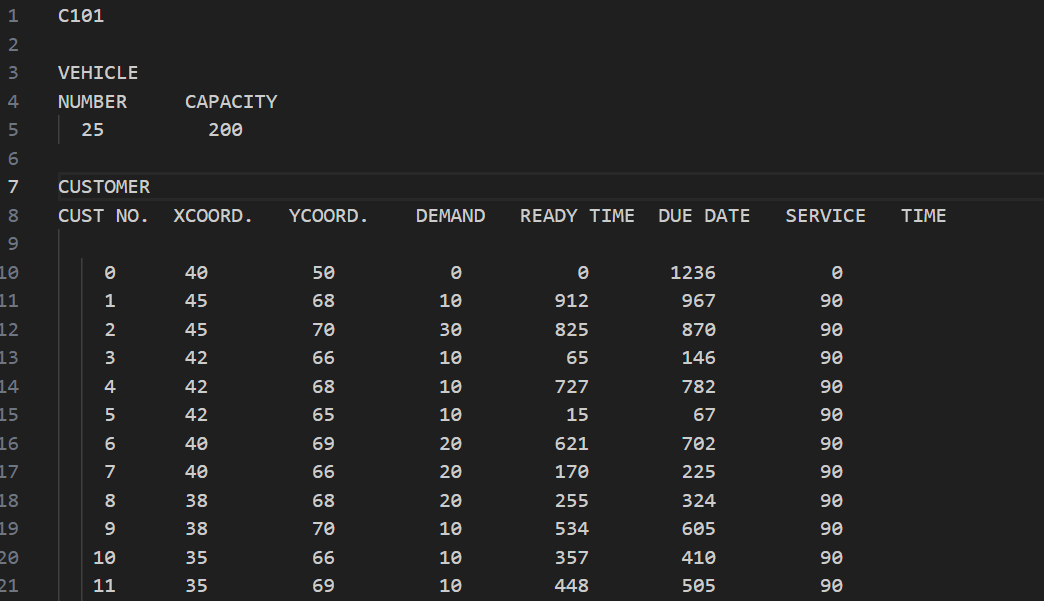

We can see here that the name of the instance is "C101", then we have the informations concerning the vehicles : the number and the capacity of each vehicle. 

This instance contains : 100 customers (since we have a hundred rows), 1 depot, a maximum of 25 vehicles that have each a capacity of $Q = 200$. For each row (so customer) we have : 
- The **customer number** that represents each node 
- The **coordinates** that represent the location of each node ; we have XCOORD and YCOORD (coordonnées de x et y)
- The **demand** (noted $q_i$) which represents the quantity that has to be delivered to a customer that we will represent as i 
- The **ready time** (noted $a_i$) that is the earliest permitted start of service 
- The **due date** (noted $b_i$)that represents the latest permitted start of service 
- The **service time** (noted $d_i$) which is then the duration of service at the customer


By default our depot is at the node (0) so it's located at (40;50). For that row we have no demand, so no ready time and no service duration. But the duration is 1236 meaning that the end of the depot's time window is 1236.

As precised earlier the input data is stored in a table where each row represents a node For the coodinates we have 2 values per node (x and y) and one value for the due date, the ready time and the service time.

With this format the edge weights are computed automatically using Euclidean distances.

Let's try to read this file using the library :

In [4]:
import vrplib 
# To read the Solomon instance file we use : 
instance = vrplib.read_instance("C101.txt", instance_format = "solomon")
print (instance)

{'name': 'C101', 'vehicles': 25, 'capacity': 200, 'node_coord': array([[40, 50],
       [45, 68],
       [45, 70],
       [42, 66],
       [42, 68],
       [42, 65],
       [40, 69],
       [40, 66],
       [38, 68],
       [38, 70],
       [35, 66],
       [35, 69],
       [25, 85],
       [22, 75],
       [22, 85],
       [20, 80],
       [20, 85],
       [18, 75],
       [15, 75],
       [15, 80],
       [30, 50],
       [30, 52],
       [28, 52],
       [28, 55],
       [25, 50],
       [25, 52],
       [25, 55],
       [23, 52],
       [23, 55],
       [20, 50],
       [20, 55],
       [10, 35],
       [10, 40],
       [ 8, 40],
       [ 8, 45],
       [ 5, 35],
       [ 5, 45],
       [ 2, 40],
       [ 0, 40],
       [ 0, 45],
       [35, 30],
       [35, 32],
       [33, 32],
       [33, 35],
       [32, 30],
       [30, 30],
       [30, 32],
       [30, 35],
       [28, 30],
       [28, 35],
       [26, 32],
       [25, 30],
       [25, 35],
       [44,  5],
       [42, 10],
 

### **3.2 Mathematical representation of the data**

Here the problem is modelled as a directed graph that we name $G = (V,A)$ with V the set of nodes and A the set of permitted directed arcs. An arc $(i,j)$ represents a possibilty of movement between a node i and a node j.

Here are the input parameters of our model :

| Parameter | Description |
|---|---|
| $n$ | Number of customers |
| $m$ | Maximum number of vehicles |
| $Q$ | Vehicle capacity|
| $q_i$ | Demande of the customer i  |
| $(a_i,b_i)$|Earliest and latest permitted servoce start at node i |
|$d_i$ | Service duration at the node i |
|$H$ | End of the planning horizon; depot window is $[0,H]$| 
| $t_{ij}$ | Travel time from $i$ to $j$ when departing in slot p |
| $c_{ij}$ | Cost of arc $(i,j)$, $c_{ij}=t_{ij}$ |

Then we have the decision variables that describe the routes that can be tken and their timing :

|Parameter| Description 
|---|---|
|$x_{ij}\in{0,1}$| equals 1 if a vehicle travels directly from node (i) to node (j)|
|$z_{ij}^{p}\in{0,1}$| equals 1 if arc (i,j) is used and the vehicle departs from (i) during time slot (p)|
|$s_i$| represents the start-of-service time at node (i)|
|$\delta_i$ |represents the departure time from node (i)|
|u_i| represents the cumulative demand delivered along the route up to and including node (i)|

### **3.3. Example of representation**

We will theonstance 101 